# 02 - Decision Tree và Random Forest trên Titanic

Mục tiêu: dự đoán `Survived` bằng Decision Tree và Random Forest. Tất cả imputer và encoder được đặt trong Pipeline để tránh data leakage; tập test chỉ dùng ở bước đánh giá cuối.

## 1. Load data và EDA ngắn

In [1]:
from pathlib import Path
import ast
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 24
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

NOTEBOOK_NAME = "02_titanic_dt_rf"
DATASET_NAME = "titanic"
df = pd.read_csv(DATA_DIR / "titanic_train.csv")
print("Shape:", df.shape)
print("Missing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing"))
print("Phân bố target:")
display(df["Survived"].value_counts(normalize=True).rename("proportion").to_frame())
display(df.head())


Shape: (891, 12)
Missing values:


,missing
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0


Phân bố target:


,proportion
Survived,
0,0.616162
1,0.383838


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


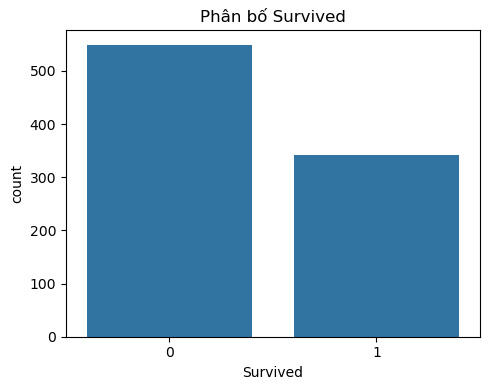

In [2]:
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="Survived")
plt.title("Phân bố Survived")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_titanic_target_distribution.png", dpi=150)
plt.show()


## 2. Tiền xử lý và chia dữ liệu

In [3]:
data = df.copy()
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
target = "Survived"
drop_columns = ["PassengerId", "Name", "Ticket", "Cabin", target]
X = data.drop(columns=drop_columns)
y = data[target]
categorical_features = ["Sex", "Embarked"]
numeric_features = [column for column in X.columns if column not in categorical_features]
preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_features),
    ]
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train/test:", X_train.shape, X_test.shape)


Train/test: (712, 8) (179, 8)


## 3. Tuning bằng cross-validation

In [4]:
dt_search = GridSearchCV(
    Pipeline([("preprocessor", preprocessor), ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    {
        "model__max_depth": [2, 3, 5, 8, None],
        "model__min_samples_leaf": [1, 3, 5],
        "model__class_weight": [None, "balanced"],
    },
    scoring="roc_auc", cv=5, n_jobs=-1, return_train_score=True, error_score=np.nan
)
dt_search.fit(X_train, y_train)
print("Decision Tree best params:", dt_search.best_params_)
print("Decision Tree CV ROC AUC:", dt_search.best_score_)

rf_search = GridSearchCV(
    Pipeline([("preprocessor", preprocessor), ("model", RandomForestClassifier(
        random_state=RANDOM_STATE, n_jobs=-1
    ))]),
    {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 10],
        "model__class_weight": [None, "balanced"],
    },
    scoring="roc_auc", cv=5, n_jobs=-1, return_train_score=True, error_score=np.nan
)
rf_search.fit(X_train, y_train)
print("Random Forest best params:", rf_search.best_params_)
print("Random Forest CV ROC AUC:", rf_search.best_score_)


Decision Tree best params: {'model__class_weight': 'balanced', 'model__max_depth': 3, 'model__min_samples_leaf': 1}
Decision Tree CV ROC AUC: 0.853537490896425


Random Forest best params: {'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__n_estimators': 200}
Random Forest CV ROC AUC: 0.860468583430966


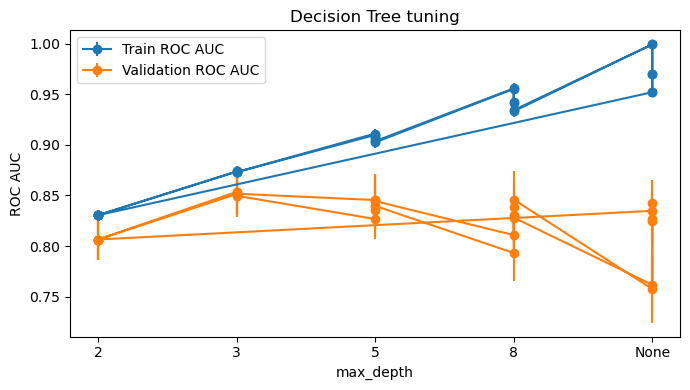

In [5]:
cv_results = pd.DataFrame(dt_search.cv_results_)
plt.figure(figsize=(7, 4))
plt.errorbar(
    cv_results["param_model__max_depth"].astype(str),
    cv_results["mean_train_score"],
    yerr=cv_results["std_train_score"] / np.sqrt(5),
    marker="o", label="Train ROC AUC",
)
plt.errorbar(
    cv_results["param_model__max_depth"].astype(str),
    cv_results["mean_test_score"],
    yerr=cv_results["std_test_score"] / np.sqrt(5),
    marker="o", label="Validation ROC AUC",
)
plt.xlabel("max_depth")
plt.ylabel("ROC AUC")
plt.title("Decision Tree tuning")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "02_titanic_dt_tuning.png", dpi=150)
plt.show()


## 4. Đánh giá trên tập test

In [6]:
def evaluate_model(name, estimator, X_test, y_test, feature_names, figure_prefix):
    y_pred = estimator.predict(X_test)
    y_score = estimator.predict_proba(X_test)[:, 1]
    metrics = {
        "notebook": NOTEBOOK_NAME,
        "dataset": DATASET_NAME,
        "model": name,
        "best_params": str(estimator.best_params_),
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_score),
    }
    print(f"\n{name} - classification report")
    print(classification_report(y_test, y_pred, zero_division=0))
    print(f"ROC AUC: {metrics['roc_auc']:.4f}")
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
    plt.title(f"{name} - confusion matrix")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{figure_prefix}_{name.lower().replace(' ', '_')}_confusion_matrix.png", dpi=150)
    plt.show()
    RocCurveDisplay.from_predictions(y_test, y_score, name=name)
    plt.title(f"{name} - ROC curve")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{figure_prefix}_{name.lower().replace(' ', '_')}_roc_curve.png", dpi=150)
    plt.show()
    return metrics


def append_results(rows):
    results_path = FIG_DIR / "results_summary.csv"
    columns = ["notebook", "dataset", "model", "best_params", "accuracy",
               "precision", "recall", "f1", "roc_auc"]
    old_rows = []
    if results_path.exists():
        with results_path.open(newline="", encoding="utf-8") as file:
            old_rows = list(csv.DictReader(file))
    old_rows = [row for row in old_rows if row.get("notebook") != NOTEBOOK_NAME]
    with results_path.open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=columns)
        writer.writeheader()
        writer.writerows(old_rows)
        writer.writerows(rows)



DecisionTree - classification report
              precision    recall  f1-score   support

           0       0.83      0.89      0.86       110
           1       0.80      0.71      0.75        69

    accuracy                           0.82       179
   macro avg       0.82      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179

ROC AUC: 0.8292


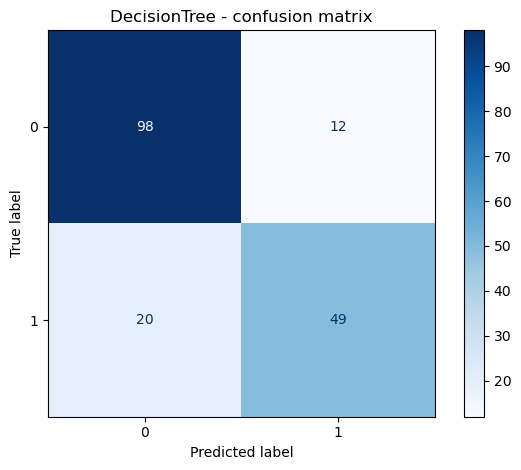

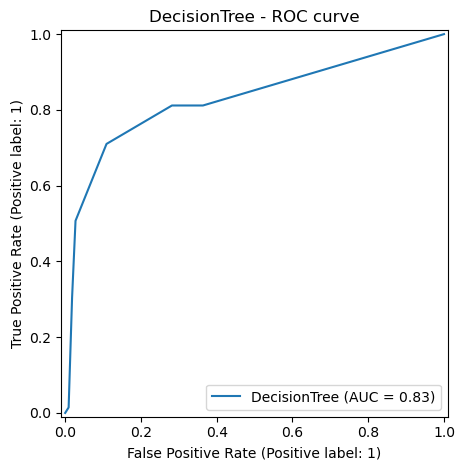


RandomForest - classification report
              precision    recall  f1-score   support

           0       0.88      0.91      0.90       110
           1       0.85      0.81      0.83        69

    accuracy                           0.87       179
   macro avg       0.87      0.86      0.86       179
weighted avg       0.87      0.87      0.87       179

ROC AUC: 0.8873


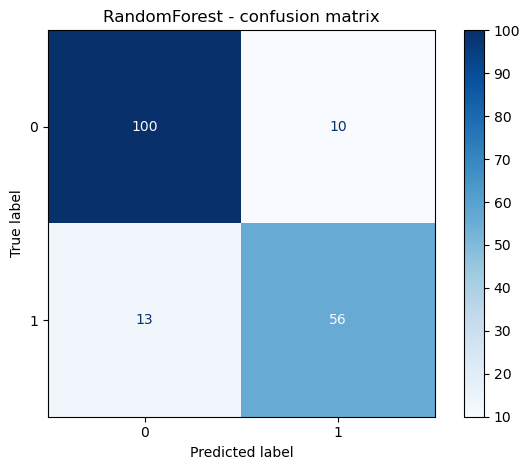

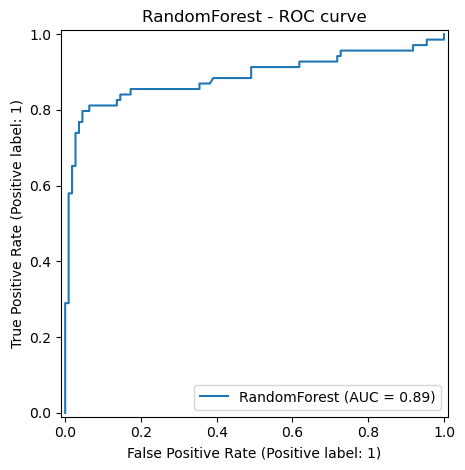

,model,accuracy,precision,recall,f1,roc_auc
0,DecisionTree,0.821229,0.803279,0.710145,0.753846,0.829249
1,RandomForest,0.871508,0.848485,0.811594,0.829630,0.887286


In [7]:
titanic_results = [
    evaluate_model("DecisionTree", dt_search, X_test, y_test, None, "02_titanic"),
    evaluate_model("RandomForest", rf_search, X_test, y_test, None, "02_titanic"),
]
results = pd.DataFrame(titanic_results)
display(results[["model", "accuracy", "precision", "recall", "f1", "roc_auc"]])


## 5. Feature importance và nhận xét

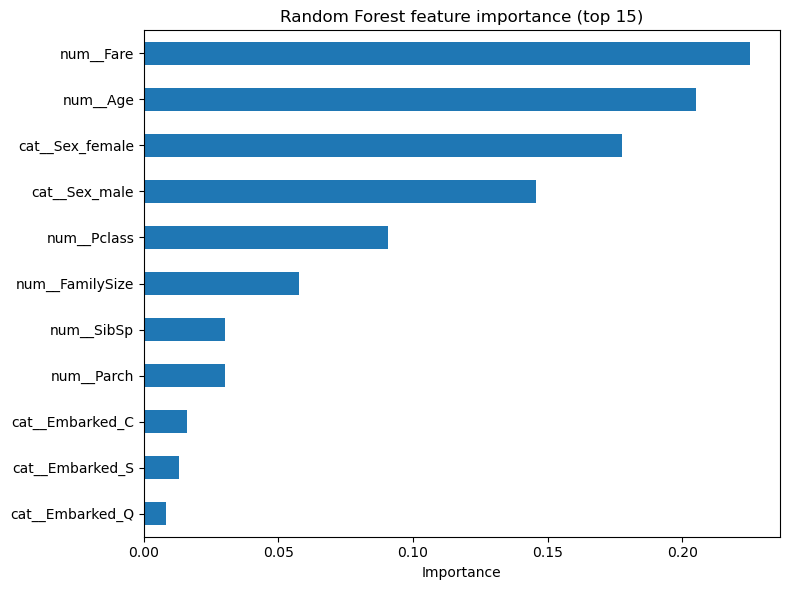

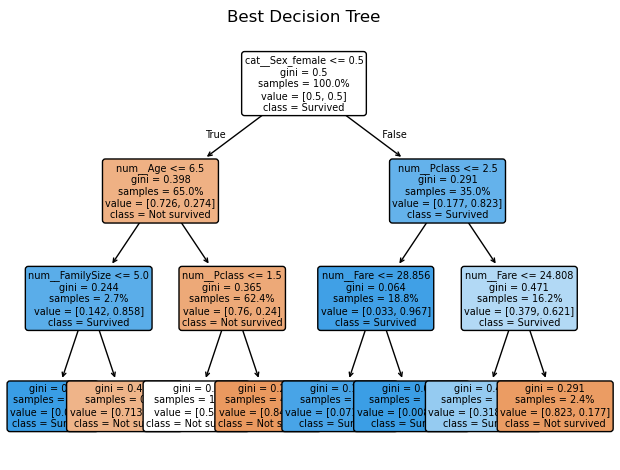

In [8]:
best_rf = rf_search.best_estimator_
feature_names = best_rf.named_steps["preprocessor"].get_feature_names_out()
importance = pd.Series(
    best_rf.named_steps["model"].feature_importances_, index=feature_names
).sort_values(ascending=True)
plt.figure(figsize=(8, 6))
importance.tail(15).plot.barh()
plt.title("Random Forest feature importance (top 15)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_titanic_rf_feature_importance.png", dpi=150)
plt.show()

plot_tree(
    dt_search.best_estimator_.named_steps["model"],
    feature_names=dt_search.best_estimator_.named_steps["preprocessor"].get_feature_names_out(),
    class_names=["Not survived", "Survived"],
    filled=True, rounded=True, max_depth=3, proportion=True, fontsize=7,
)
plt.title("Best Decision Tree")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_titanic_best_tree.png", dpi=150)
plt.show()


Decision Tree dễ diễn giải nhưng có xu hướng overfit khi cây sâu; Random Forest giảm phương sai nhờ trung bình nhiều cây nên thường ổn định hơn. `Cabin` được bỏ theo ghi đè vì thiếu quá nhiều; `FamilySize` được thêm từ `SibSp` và `Parch`.

In [9]:
append_results(titanic_results)
print("Đã cập nhật figures/results_summary.csv cho notebook 02.")


Đã cập nhật figures/results_summary.csv cho notebook 02.
